# Notebook 2 — Real mmWave Radar Data

**CSCI 4900/6900 · Real-data lesson · English · No radar hardware required**

Compute **Range Spectrum, Doppler Spectrum, and Angular Spectrum** from a bundled frame of
**real 77 GHz complex ADC/IQ measurements**. Then use a bundled 30-frame, single-channel subset to explore **STFT and a time–Doppler spectrogram**, and to measure **how far the person moves in one second**. No simulated signals are generated here.
The source has no independent target ground truth; spectral peaks are estimates, not verified labels.

This notebook is standalone. Start with a fresh kernel and run the core cells from top to bottom.
It defines all imports, plotting helpers, parameters, and intermediate arrays itself.
You do not need to execute [Notebook 1 — Simulation](lab7_mmwave_simulation.ipynb) first,
though that notebook introduces the underlying concepts.
Install the dependencies using the [README instructions](README.md) before class. Use your existing Python installation; a dedicated virtual environment is optional.

**Class route:** complete Sections 1–7 using the bundled recording. Install dependencies before starting.

In [1]:
from pathlib import Path  # Build file and folder paths.
import hashlib  # Compute a checksum to verify the data.
import json  # Read the radar settings from JSON.
import numpy as np  # Work with arrays and calculate FFTs.
import matplotlib.pyplot as plt  # Create plots.
from IPython.display import display, Markdown  # Support formatted notebook text.

# Support launching from the lab directory or repository root.
LAB = Path.cwd()  # Start with the current working folder.
if not (LAB / "lab7_mmwave_real_data.ipynb").exists():  # Check whether this is the lab folder.
    LAB = LAB / "Lab-7-mmWave"  # Look inside the lab subfolder.
if not (LAB / "lab7_mmwave_real_data.ipynb").exists():  # Check the resulting path again.
    raise FileNotFoundError("Start Jupyter from Lab-7-mmWave or the repository root.")  # Explain how to fix the path.
FIG = LAB / "figures" / "real_data"  # Choose where to save the figures.
FIG.mkdir(parents=True, exist_ok=True)  # Create missing output folders.
plt.rcParams.update({  # Set shared plotting defaults.
    "figure.figsize": (10, 3.5), "figure.dpi": 110,  # Set figure size in inches and screen resolution.
    "axes.spines.top": False, "axes.spines.right": False,  # Hide the top and right borders.
    "axes.grid": True, "grid.alpha": 0.2, "font.size": 10,  # Use a faint grid and readable text.
})  # Apply the plotting settings.
C = 299_792_458.0  # Speed of light in meters per second.

def db_power(power, reference=None, floor=-60):  # Convert power to decibels relative to a reference.
    # Input power |X|^2; use 10 log10. The specified reference is 0 dB, not dBm.
    power = np.asarray(power, dtype=float)  # Convert the input to a floating-point array.
    if reference is None:  # Use the peak when no reference is supplied.
        reference = float(np.max(power))  # Make the largest power value the 0 dB reference.
    reference = max(float(reference), np.finfo(float).tiny)  # Prevent division by zero.
    return 10 * np.log10(np.maximum(power / reference, 10.0**(floor / 10)))  # Convert to dB and limit the minimum.

def finish(name):  # Save and display the current figure.
    plt.tight_layout()  # Adjust spacing so labels fit.
    plt.savefig(FIG / f"{name}.png", dpi=140, bbox_inches="tight")  # Save a PNG with minimal empty margins.
    plt.show()  # Display the figure in the notebook.

print("NumPy:", np.__version__)  # Report the installed NumPy version.
print("Environment ready; real measurements will be loaded from the bundled local file.")  # Confirm that setup is complete.

NumPy: 2.5.3
Environment ready; real measurements will be loaded from the bundled local file.


## 1. Load and inspect real I/Q

Now use [Gao et al.'s public example](https://github.com/Xiangyu-Gao/mmWave-radar-signal-processing-and-microDoppler-classification).
The original file contains 30 frames. The first frame is bundled here at approximately 632 KB for the three spectra. A second, approximately 2.3 MB subset keeps TX0/RX0 across all 30 frames for STFT. Both work offline without downloading the full dataset.
See [data/uw/README.md](data/uw/README.md) for provenance, the pinned version, SHA-256 hashes, lossless extraction, and the MIT license.

<p>
  <img src="data/uw/pms1000.jpg" alt="Upstream pms1000 scene photograph showing a person in an outdoor parking lot, with the face obscured in the original image" width="720">
</p>

**Scene photo for the `pms1000` example.** The upstream repository supplies this [same-name photograph](https://github.com/Xiangyu-Gao/mmWave-radar-signal-processing-and-microDoppler-classification/blob/c49a101b8ffe75f79abfa75b46b926c8592c7e48/template%20data/pms1000.jpg) beside `pms1000_30fs.mat`.
It shows a person in a parking lot. The MAT file contains complex radar I/Q samples; the photograph is a separate file.
The repository provides no frame-index or timestamp mapping between this photograph and our extracted frame 0, and no independent range, velocity, or angle labels for that frame.
Use the photograph as scene context when interpreting clutter and possible target returns. Image credit: Xiangyu Gao et al.; [upstream MIT license](data/uw/LICENSE.upstream.txt).

<p>
  <img src="assets/uw_radar_testbed.jpg" alt="FMCW radar testbed with a red AWR1642 BOOST radar board and a green DCA1000 EVM capture board" width="400">
  <img src="assets/uw_vehicle_platform.png" alt="Radar in a white enclosure on the roof rack of a blue car during data collection" width="418">
</p>

**Figure 1. Published radar testbed and data-collection platform.** Left: the red AWR1642 BOOST radar board and green DCA1000 EVM capture board. Right: the vehicle-mounted setup used for data collection.
Reproduced from Figure 1 in [Gao et al., *Experiments with mmWave Automotive Radar Test-bed*](https://arxiv.org/html/1912.12566v4#S1.F1), under [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). See [image credits](assets/README.md).

### 1.1 Meet the AWR1642BOOST board

**AWR1642** is Texas Instruments' radar chip; **AWR1642BOOST** is the evaluation board built around it.
The red board in Figure 1 includes the chip, PCB antennas, and interfaces for programming and communication.
It lets researchers develop and evaluate FMCW radar applications. [TI board overview](https://www.ti.com/tool/AWR1642BOOST).

| Part or capability | What it does | Connection to this tutorial |
|---|---|---|
| **76–81 GHz radio** | Generates and receives millimeter-wave signals. | The recording uses a nominal 77 GHz carrier. |
| **2 TX channels** | Send chirps through two transmit antennas. | In this recording, TX0 and TX1 take turns within each loop. |
| **4 RX channels** | Receive echoes at four antenna positions. | Phase differences across RX channels carry angle information. |
| **Mixers and ADCs** | Convert echoes to lower-frequency beat signals and digitize them. | We load complex baseband samples, `I + 1j*Q`; the ADC does not directly sample the 77 GHz carrier. |
| **C674x DSP** | Provides onboard computing for radar signal processing. | Here, we compute the spectra in Python on recorded samples. |
| **Arm Cortex-R4F MCU** | Runs application and control software. | It supports the embedded radar application. |

Hardware specifications: [TI AWR1642 device documentation](https://www.ti.com/product/AWR1642).
The carrier frequency, chirp schedule, and sample counts used here come from the [recording configuration](data/uw/README.md).

<p>
  <img src="assets/uw_awr1642_block_diagram.png" alt="AWR1642 chip diagram with four receiver chains highlighted in red, two transmitters, the digital front end, Cortex-R4F MCU, C674x DSP, and LVDS interface" width="900">
</p>

**Figure 2. Inside the AWR1642 chip.** The red dashed box highlights the four receiver chains.
Source: [Gao et al., Figure 2](https://arxiv.org/html/1912.12566v4#S3.F2), which credits Texas Instruments. See [image credits](assets/README.md).

**Read the receiver chain from left to right:**

1. **LNA** (low-noise amplifier) amplifies the weak echo. The **mixer** combines it with a local chirp reference to produce a lower-frequency beat signal.
2. **IF** (intermediate-frequency circuitry) conditions the signal; the **ADC** converts it to digital samples. The **digital front end** filters and decimates the samples before buffering and transfer.
3. The **DSP/MCU** support onboard processing and control; **LVDS** provides a path for raw data capture through the DCA1000.

The diagram labels channels **TX1–TX2 / RX1–RX4**. Our Python code uses zero-based labels **TX0–TX1 / RX0–RX3** for the same channel counts.

**Why are there two boards in the photo?** The red AWR1642BOOST performs radar sensing.
The green **DCA1000EVM** captures its raw ADC stream over **LVDS** (a high-speed electrical interface)
and forwards it to a PC over Ethernet for storage and processing. [TI DCA1000EVM overview](https://www.ti.com/tool/DCA1000EVM).

```text
AWR1642BOOST: TX chirps -> scene -> RX echoes -> mixing + ADC -> I/Q samples
                                                                   |
                                                                  LVDS
                                                                   v
DCA1000EVM: capture -> Ethernet -> PC recording -> saved data file

This tutorial: bundled frame -> Range FFT -> Doppler FFT -> angle estimation
```

**Connect the hardware to the array:** `2 TX` and `4 RX` describe the AWR1642's radio channels.
`255 loops` and `128 samples` describe this recording's acquisition settings; they are not fixed board dimensions.
The next section explains how these four numbers become an array.

### 1.2 Read the shape: loops, TX, RX, and samples

In the loading cell below, `measured_all` holds the stored `adc` array.
The shape `[255, 2, 4, 128]` describes **one recorded frame** with axes
`[loop, TX, RX, ADC sample]`. A frame groups repeated chirps for processing.
A **chirp** is one transmitted frequency sweep.

| Dimension | Meaning in this recording |
|---|---|
| **255 loops** | The two-TX transmit sequence repeats 255 times within the frame. Each loop contains one chirp from TX0 and one from TX1. |
| **2 TX** | Two transmit antenna channels. TX0 and TX1 transmit in alternating chirps, rather than simultaneously. |
| **4 RX** | Four receive antenna channels record the echo simultaneously during each transmitted chirp. |
| **128 samples** | Each RX records 128 complex ADC values within each chirp. Each value contains both I and Q: `I + 1j*Q`. |

```text
One frame
  loop 0:    TX0 chirp -> TX1 chirp
  loop 1:    TX0 chirp -> TX1 chirp
  ...
  loop 254:  TX0 chirp -> TX1 chirp

During each transmitted chirp, all four RX channels record:
  RX0: [sample 0, sample 1, ..., sample 127]
  RX1: [sample 0, sample 1, ..., sample 127]
  RX2: [sample 0, sample 1, ..., sample 127]
  RX3: [sample 0, sample 1, ..., sample 127]
         Each sample is a complex I/Q value.
```

There are **255 × 2 = 510 transmitted chirps** and
**255 × 2 × 4 × 128 = 261,120 complex samples** in this frame.
The RX count does not multiply the number of transmitted chirps: the receivers observe the same transmission in parallel.
I and Q are the two components of each sample, not additional samples or another array axis.

With Python's zero-based indexing, `measured_all[10, 1, 2, 50]` means:
the **11th loop**, the chirp transmitted by **TX1**, the echo on **RX2**, and the **51st ADC sample**.
Here TX0/TX1 and RX0–RX3 are zero-based channel labels.

Selecting `measured_all[:, 0, :, :]` keeps TX0 and removes the TX axis, leaving
`[255 chirps, 4 RX, 128 samples]`. There is one TX0 chirp per loop:

| Remaining axis | What varies | Spectrum |
|---|---|---|
| 2: 128 samples | Fast time within one chirp | Range Spectrum |
| 0: 255 loops | Slow time across repeated chirps from TX0 | Doppler Spectrum |
| 1: 4 RX | Receiver position, using complex values at one range–Doppler cell | Angular Spectrum |

### 1.3 Published FMCW configuration

<p>
  <img src="assets/uw_fmcw_configuration.png" alt="Table I: start frequency 77 GHz; sweep bandwidth 670 MHz; slope 21 MHz/us; frame rate 30 fps; sampling frequency 4000 ksps; chirps per frame 255; samples per chirp 128; transmitters and receivers 2 and 4" width="610">
</p>

**Table I. Configuration reported in the paper.** Reproduced from [Gao et al., Table I](https://arxiv.org/html/1912.12566v4#S5.T1). See [image credits](assets/README.md).

* **4000 ksps = 4 MS/s** describes sampling within a chirp; **30 fps** describes whole frames per second. Neither is the same-TX chirp repetition rate used for Doppler processing.
* The paper's **255 chirps** entry needs the storage convention explained above: this bundled two-TX frame contains **255 loops**, giving **255 chirps per TX** and **510 transmitted chirps in total**. The reshape follows the upstream processing code.
* The table uses rounded values. The notebook uses [metadata.json](data/uw/metadata.json), including a slope of **21.0017 MHz/µs**, to compute spectral coordinates.

### 1.4 Dataset-specific processing assumptions

* The file has shape `[255 loops, 2 TX, 4 RX, 128 samples]`. The two TXs transmit alternately using TDM-MIMO.
* We fix **TX index 0** and keep its four RX channels, obtaining `[255, 4, 128]`. The main pipeline does not combine TXs.
* The same-TX slow-time interval is **120 µs**, following the upstream parameters. It is not `1/fs` and must not be multiplied by two again.
* The Range FFT uses the complete unshifted positive-beat frequency interval, consistent with the upstream pipeline.
* The four RXs follow the upstream $\lambda/2$ ULA ordering. Without independent phase calibration, angles are spectral estimates in that coordinate convention.

The paper and repository script describe different board models, so we refer to these as TI 77 GHz measurements.
We do not infer target distance from the filename or treat a selected peak as a verified pedestrian label.

Preserve complex phase throughout the processing chain. Convert to power only for plots or power averaging.


File axes [loop, TX, RX, sample]: (255, 2, 4, 128)
Processing axes [chirp, antenna, sample]: (255, 4, 128)
Example measured values: [-127.-17.j  -63.-13.j  -34. +3.j  -66.+11.j]
ADC array SHA-256 verified


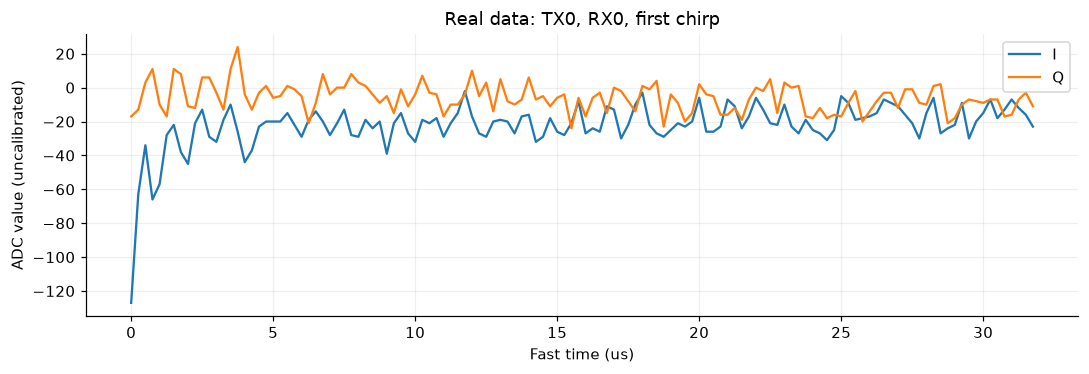

In [2]:
meta = json.loads((LAB / "data/uw/metadata.json").read_text(encoding="utf-8"))  # Load the dataset description and radar settings.
with np.load(LAB / "data/uw" / meta["file"], allow_pickle=False) as data:  # Open the bundled array file without pickle.
    measured_all = data["adc"]  # Read the complex array: [255 loops, 2 TX, 4 RX, 128 samples].
    assert data["frame_index"].item() == meta["frame_index_zero_based"]  # Confirm that this is the expected frame.
assert measured_all.shape == tuple(meta["shape"])  # Check all four array dimensions.
assert np.iscomplexobj(measured_all) and np.isfinite(measured_all).all()  # Require complex values without NaN or infinity.
payload = measured_all.astype("<c8").tobytes(order="C")  # Convert to consistent little-endian complex64 bytes for hashing.
assert hashlib.sha256(payload).hexdigest() == meta["adc_payload_sha256_little_endian_c_order"]  # Verify the array's checksum.
real_adc = measured_all[:, 0, :, :]  # Keep TX0: [255 chirps, 4 RX, 128 samples].
print("File axes [loop, TX, RX, sample]:", measured_all.shape)  # Show the original four-dimensional shape.
print("Processing axes [chirp, antenna, sample]:", real_adc.shape)  # Show the shape after selecting TX0.
print("Example measured values:", real_adc[0, 0, :4])  # Show four I/Q samples from the first chirp and RX0.
print("ADC array SHA-256 verified")  # Confirm that the integrity check passed.

plt.figure()  # Start a new figure.
real_fast_us = np.arange(real_adc.shape[2]) / meta["sample_rate_hz"] * 1e6  # Convert sample indices to microseconds.
plt.plot(real_fast_us, real_adc[0, 0].real, label="I")  # Plot the real component of the first chirp on RX0.
plt.plot(real_fast_us, real_adc[0, 0].imag, label="Q")  # Plot the imaginary component of the same samples.
plt.xlabel("Fast time (us)")  # Label the within-chirp time axis.
plt.ylabel("ADC value (uncalibrated)")  # Label raw ADC values, which are not calibrated voltages.
plt.title("Real data: TX0, RX0, first chirp")  # Identify the selected transmit/receive channels.
plt.legend()  # Identify the I and Q curves.
finish("10_real_iq")  # Save and display the raw I/Q plot.

### 1.5 From I/Q samples to radar spectra

<p>
  <img src="assets/uw_processing_workflow.png" alt="Radar processing workflow: ADC I/Q feeds Range FFT, then Velocity FFT and Angle FFT; other branches show CFAR detection, STFT, a point cloud, and a range-angle heatmap" width="840">
</p>

**Figure 3. The paper's radar-processing workflow.** Reproduced from [Gao et al., Figure 4](https://arxiv.org/html/1912.12566v4#S4.F4). See [image credits](assets/README.md).

Follow the data axes: **Range FFT** acts across ADC samples, **Velocity FFT** (Doppler FFT) acts across repeated same-TX chirps, and **Angle FFT** acts across antenna positions.
The term **3DFFT** refers to these three transform axes. **CFAR** (constant false alarm rate) is a separate detection step.

In this notebook, Sections 2–3 perform the first two FFTs. Section 4 scans spatial phase with **conventional beamforming** to obtain the Angular Spectrum and a **range–angle (RA) heatmap**.
Section 5 follows the **STFT** (short-time Fourier transform) branch to show how Doppler content changes over time. Section 7 combines range and Doppler across all 30 frames to measure how far the person moves. CFAR detection and point-cloud generation belong to the paper's broader pipeline and are outside this notebook's exercises.

**Before running:** which axis of `[255, 4, 128]` should each spectrum use? Check your answer against the axis table in Section 1.2.

## 2. Range Spectrum

Rebuild coordinates from the metadata rather than reusing the simulation dimensions.
The steps remain **ADC → Hann window → fast-time FFT → average power**.
Raw complex ADC values are not voltages. The plot uses dB relative to its peak, not dBm.

For chirp slope $S$ and sample rate $f_s$, the positive-beat range coordinate is
$R_k=c\,k f_s/(2S N_R)$. Use the metadata values, not an assumed configuration.
Complex I/Q requires a complex FFT, not `rfft`. This dataset follows the upstream
unshifted positive-beat convention; other ADC/IF formats may need a different frequency mapping.


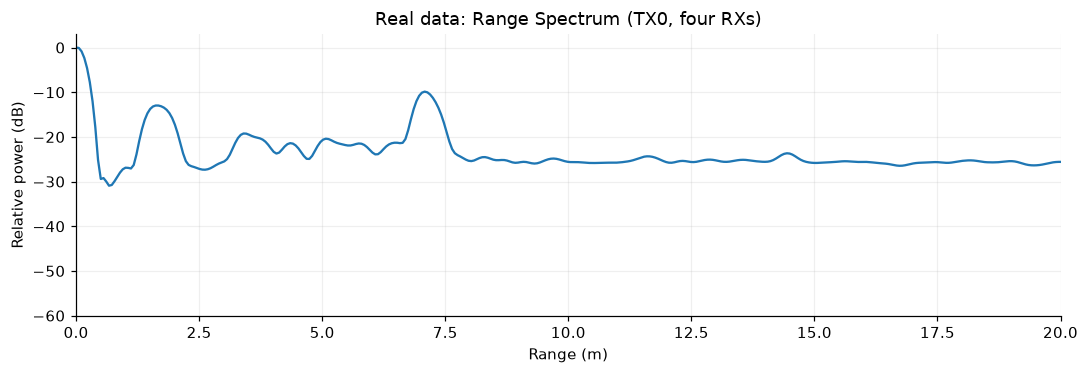

Range-resolution scale ≈ 0.223 m
Velocity-resolution scale ≈ 0.064 m/s


In [3]:
Mr, Ar, Nr = real_adc.shape  # Get the chirp, RX antenna, and ADC sample counts.
fsr = meta["sample_rate_hz"]  # Read the ADC sampling rate in samples per second.
Sr = meta["slope_hz_per_s"]  # Read the chirp frequency slope in Hz per second.
Tsr = meta["same_tx_chirp_interval_s"]  # Read the time between successive TX0 chirps.
lamr = C / meta["fc_hz"]  # Convert carrier frequency to wavelength in meters.
NRr, NDr = 512, 256  # Choose the range and Doppler FFT lengths.
wrr = np.hanning(Nr)  # Create a Hann window for the ADC samples.
Rr = np.fft.fft(real_adc*wrr[None, None, :], n=NRr, axis=2) / wrr.sum()  # Window samples, FFT along fast time, and normalize.
rr = np.arange(NRr)*fsr/NRr*C/(2*Sr)  # Convert positive-beat FFT bins to range in meters.
real_range_power = np.mean(abs(Rr)**2, axis=(0, 1))  # Average power over chirps and RX antennas.

plt.figure()  # Start a new figure.
plt.plot(rr, db_power(real_range_power))  # Plot average range power relative to its peak.
plt.xlim(0, 20)  # Display ranges from 0 to 20 meters.
plt.ylim(-60, 3)  # Set the displayed power limits in dB.
plt.xlabel("Range (m)")  # Label the range axis.
plt.ylabel("Relative power (dB)")  # Label power relative to the reference.
plt.title("Real data: Range Spectrum (TX0, four RXs)")  # Describe the channels used in this spectrum.
finish("11_real_range")  # Save and display the Range Spectrum.
print(f"Range-resolution scale ≈ {C/(2*Sr*Nr/fsr):.3f} m")  # Estimate range resolution from the observed bandwidth.
print(f"Velocity-resolution scale ≈ {lamr/(2*Mr*Tsr):.3f} m/s")  # Estimate velocity resolution from the chirp observation time.

**Observation task:** record the two most prominent range regions. Can you tell which one is moving from the range spectrum alone?

## 3. Doppler Spectrum

Compute versions with and without slow-time mean removal, and plot them using a common reference.
For a reproducible example cell, select the largest value after mean removal within $1<R<20$ m and $0.2<|v|<3$ m/s.
This is a repeatable selection rule, **not a validated target detector**:
a strong peak may come from multipath, sidelobes, noise, or several scattering points. No CFAR, clustering, or tracking is performed.

At a fixed range and RX channel, take an FFT across chirps and map $f_D$ to
$v=\lambda f_D/2$. Both the FFT and its frequency axis must be shifted together.
Here $T_{\rm slow}=120\,\mu s$ is the same-TX interval.

**Static removal:** subtract the complex slow-time mean before the Doppler window:
$R_{\rm moving}=R-\operatorname{mean}_{\rm chirp}(R)$.
This can suppress walls and desks, but also stationary targets of interest and very slow motion.
Compare the two maps with their shared power reference.


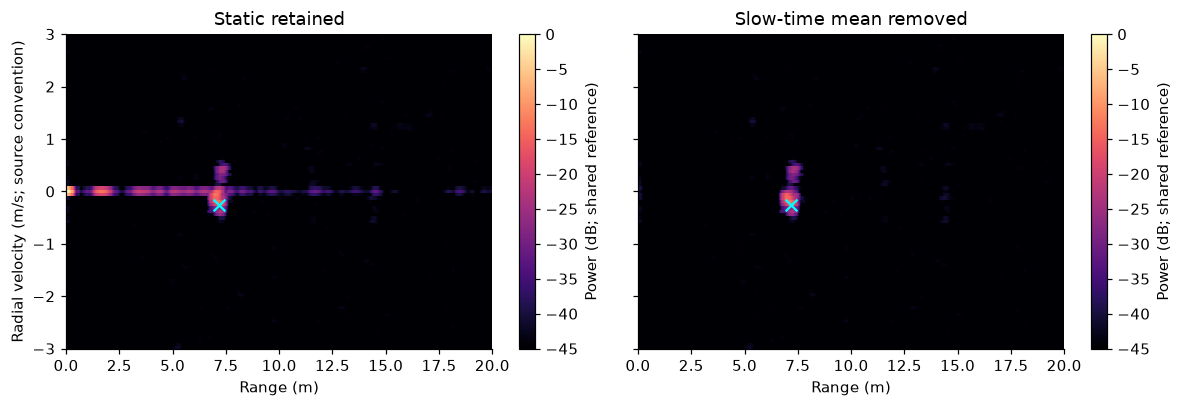

Selected spectral peak: R=7.19 m, v=-0.25 m/s


In [4]:
wdr = np.hanning(Mr)  # Create a Hann window across chirps.
RDr_all = np.fft.fftshift(  # Center zero Doppler for the data that retains static reflections.
    np.fft.fft(Rr*wdr[:, None, None], n=NDr, axis=0), axes=0  # Window and FFT along the chirp axis, then shift that axis.
) / wdr.sum()  # Normalize by the Doppler window's sum.
Rr_moving = Rr - Rr.mean(axis=0, keepdims=True)  # Subtract the complex mean across chirps to suppress static returns.
RDr = np.fft.fftshift(  # Center zero Doppler for the static-suppressed data.
    np.fft.fft(Rr_moving*wdr[:, None, None], n=NDr, axis=0), axes=0  # Apply the same window, FFT, and axis shift.
) / wdr.sum()  # Use the same normalization for a fair comparison.
vr = np.fft.fftshift(np.fft.fftfreq(NDr, d=Tsr))*lamr/2  # Convert shifted Doppler frequencies to radial velocity.
Pr_all = np.mean(abs(RDr_all)**2, axis=1)  # Average RX power while retaining static reflections.
Pr = np.mean(abs(RDr)**2, axis=1)  # Average RX power after static suppression.
real_gate = ((rr[None, :] > 1) & (rr[None, :] < 20)  # Limit example peak selection to ranges between 1 and 20 meters.
             & (abs(vr[:, None]) > .2) & (abs(vr[:, None]) < 3))  # Also require radial speed magnitude between 0.2 and 3 m/s.
real_di, real_ri = np.unravel_index(np.argmax(np.where(real_gate, Pr, -np.inf)), Pr.shape)  # Find the strongest allowed cell's Doppler and range indices.

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)  # Create two maps with a shared velocity axis.
ref = Pr_all.max()  # Use one power reference for both maps.
for ax, power, title in zip(axes, [Pr_all, Pr], ["Static retained", "Slow-time mean removed"]):  # Pair each plot with its data and title.
    im = ax.pcolormesh(rr, vr, db_power(power, ref), shading="auto", cmap="magma", vmin=-45, vmax=0)  # Draw range–velocity power as a heatmap.
    ax.scatter([rr[real_ri]], [vr[real_di]], marker="x", c="cyan", s=60)  # Mark the selected spectral cell.
    ax.set(xlim=(0, 20), ylim=(-3, 3), xlabel="Range (m)", title=title)  # Set plot limits, the range label, and the title.
    ax.grid(False)  # Hide grid lines over the heatmap.
    fig.colorbar(im, ax=ax, label="Power (dB; shared reference)")  # Explain the shared power color scale.
axes[0].set_ylabel("Radial velocity (m/s; source convention)")  # Label velocity using the dataset's sign convention.
finish("12_real_range_doppler")  # Save and display both range–Doppler maps.
print(f"Selected spectral peak: R={rr[real_ri]:.2f} m, v={vr[real_di]:+.2f} m/s")  # Report the selected range and radial velocity.

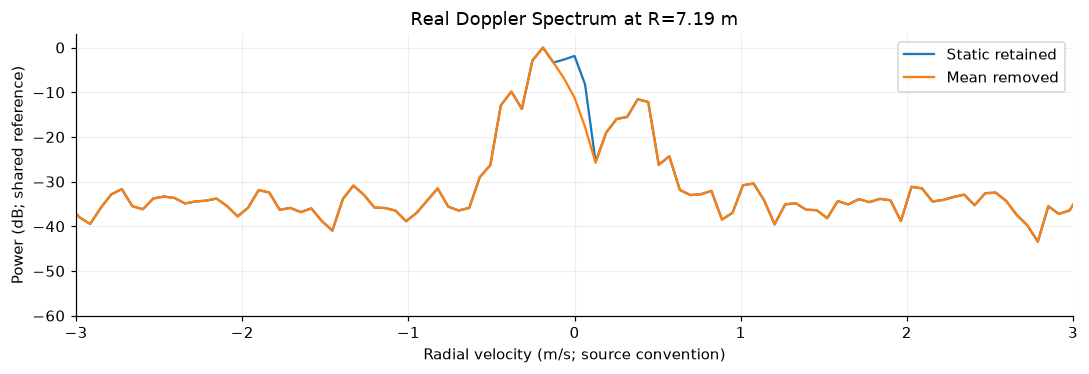

In [5]:
selected_range_m = float(rr[real_ri])  # Choose the peak's range; try 3.0, 7.0, or 12.0 to inspect another distance.
slice_ri = int(np.argmin(abs(rr-selected_range_m)))  # Find the nearest available range bin.
slice_ref = Pr_all[:, slice_ri].max()  # Use the original slice's maximum as the shared reference.
plt.figure()  # Start a new figure.
plt.plot(vr, db_power(Pr_all[:, slice_ri], slice_ref), label="Static retained")  # Plot the Doppler slice before static removal.
plt.plot(vr, db_power(Pr[:, slice_ri], slice_ref), label="Mean removed")  # Plot the same slice after static removal.
plt.xlim(-3, 3)  # Show radial velocities between −3 and +3 m/s.
plt.ylim(-60, 3)  # Set the displayed power limits in dB.
plt.xlabel("Radial velocity (m/s; source convention)")  # Label velocity using the dataset's sign convention.
plt.ylabel("Power (dB; shared reference)")  # Indicate that both curves use the same reference.
plt.title(f"Real Doppler Spectrum at R={rr[slice_ri]:.2f} m")  # Show the actual range bin used.
plt.legend()  # Identify the before/after curves.
finish("13_real_doppler_slice")  # Save and display the Doppler Spectrum.

**Observation task:** what changes near zero velocity? How does the Doppler Spectrum change when you select a different range?
A single-frame spectrum cannot recover the target's full two-dimensional velocity; it measures only the radial component along the radar's line of sight.
Velocity signs follow the processing convention and have not been independently checked with known approaching/receding motion.

## 4. Angular Spectrum

Continue using the cell selected automatically in Section 3; changing the manual range slice afterward does not change this selection.
Its four-element antenna vector contains only four spatial observations, so a broad peak is expected.
The range–angle map below uses data after slow-time mean removal and sums power over all Doppler cells.
It therefore shows spatial energy after static suppression; residual energy at small velocities may remain.

For each candidate angle, use the ULA steering vector
$a_m(\theta)=e^{j2\pi m(d/\lambda)\sin\theta}$.
The conventional beamforming spectrum is $P(\theta)=|\mathbf a(\theta)^H\mathbf z|^2/A^2$,
where $\mathbf z$ is the complex RX vector at the selected range–Doppler cell.
This scans the same spatial phase progression that an Angle FFT estimates on a uniform array.
Taking `abs(z)` first destroys the directional phase information.


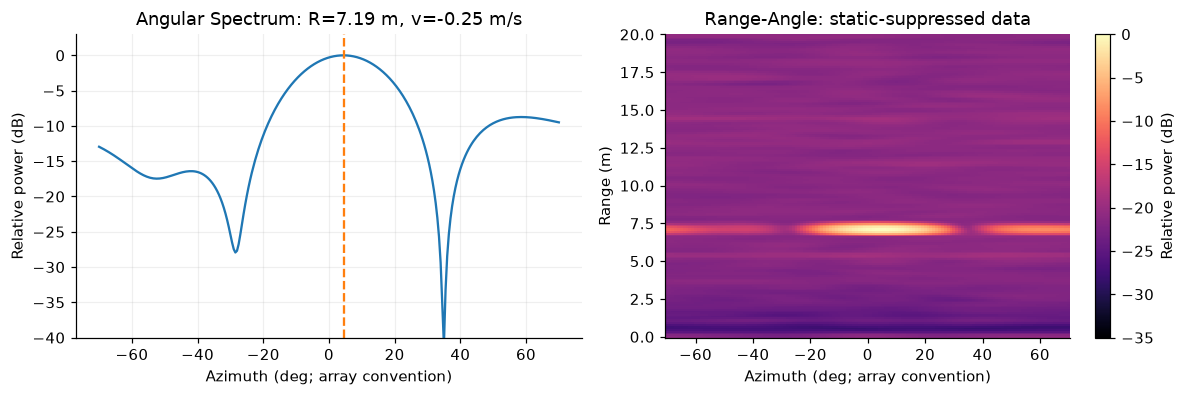

Selected cell's angular peak = +4.5 deg (no supplied ground truth or phase calibration)


In [6]:
angle_grid_real = np.linspace(-70, 70, 281)  # Scan 281 candidate angles from −70° to +70°.
ar = np.exp(1j*2*np.pi*np.arange(Ar)[:, None]*meta["rx_spacing_wavelengths"]  # Build phase factors from RX positions in wavelengths.
            * np.sin(np.deg2rad(angle_grid_real))[None, :])  # Include each angle's sine to form the steering vectors.
zr = RDr[real_di, :, real_ri]  # Extract the four complex RX values at the selected range–Doppler cell.
real_angle_power = abs(ar.conj().T @ zr)**2 / Ar**2  # Align RX phases for each angle, sum them, and compute normalized power.
real_angle_est = angle_grid_real[np.argmax(real_angle_power)]  # Select the angle with the strongest response.

# Reduce plotting density to limit temporary angle-scan memory.
real_map_angles = angle_grid_real[::2]  # Keep every second candidate angle for the map.
real_map_ranges = np.flatnonzero(rr <= 20)[::2]  # Keep every second range bin up to 20 meters.
ar_map = ar[:, ::2]  # Keep the matching steering vectors.
real_beams = np.einsum("dar,at->dtr", RDr[:, :, real_map_ranges],  # Sum antenna values: [Doppler, antenna, range] to [Doppler, angle, range].
                       ar_map.conj(), optimize=True) / Ar  # Compensate steering phase and normalize by the RX count.
real_ra_power = np.sum(abs(real_beams)**2, axis=0)  # Sum power over Doppler to form an [angle, range] map.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))  # Create panels for the angular slice and the full map.
axes[0].plot(angle_grid_real, db_power(real_angle_power))  # Plot the selected cell's Angular Spectrum.
axes[0].axvline(real_angle_est, ls="--", color="tab:orange")  # Mark the estimated angle.
axes[0].set(xlabel="Azimuth (deg; array convention)", ylabel="Relative power (dB)",  # Label angle and relative power.
            title=f"Angular Spectrum: R={rr[real_ri]:.2f} m, v={vr[real_di]:+.2f} m/s",  # Identify the selected range–Doppler cell.
            ylim=(-40, 3))  # Set the angular plot's power limits.
im = axes[1].pcolormesh(real_map_angles, rr[real_map_ranges], db_power(real_ra_power).T,  # Transpose power to plot angle horizontally and range vertically.
                        shading="auto", cmap="magma", vmin=-35, vmax=0)  # Set the heatmap style and dB color limits.
axes[1].set(xlabel="Azimuth (deg; array convention)", ylabel="Range (m)",  # Label the map's two physical coordinates.
            title="Range-Angle: static-suppressed data")  # Identify the processed data shown in the map.
axes[1].grid(False)  # Hide grid lines over the heatmap.
fig.colorbar(im, ax=axes[1], label="Relative power (dB)")  # Add the map's power color scale.
finish("14_real_angle")  # Save and display both angle plots.
del real_beams  # Release the large temporary beamforming array.
print(f"Selected cell's angular peak = {real_angle_est:+.1f} deg (no supplied ground truth or phase calibration)")  # Report the estimate and its measurement limitations.

## 5. STFT: how does Doppler content change over time?

**STFT** means **Short-Time Fourier Transform**. Take a short piece of a signal, multiply it by a window, compute an FFT, then slide the window and repeat. Stacking the local spectra preserves when each frequency component appears. See the [SciPy STFT explanation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.ShortTimeFFT.html).

| View | What it tells us |
|---|---|
| One Doppler FFT | Which radial-velocity components occur during one observation interval? |
| STFT | How do those components vary as the observation window moves? |
| Spectrogram | A heatmap of STFT power: time horizontally, Doppler frequency or radial velocity vertically, and power as color. |

For a complex slow-time signal $x[m]$ at a fixed range bin,

$$X[p,k]=\sum_{n=0}^{L-1}x[pH+n]w[n]e^{-j2\pi kn/N_{\rm FFT}}.$$

Here $L$ is the **window length**, $H$ is the **hop** in chirps, $L-H$ is the **overlap**, and $p$ identifies a window. The STFT is complex; the spectrogram displays $|X[p,k]|^2$, often in dB. We normalize each FFT by the Hann window's sum and average power over a small fixed range gate.

### 5.1 Slide a window along slow time

```text
Range FFT -> keep a fixed range gate -> preserve complex values across chirps

Window 0: chirps   0 ... 127 -> Hann window -> FFT -> spectrogram column 0
Window 1: chirps  16 ... 143 -> Hann window -> FFT -> spectrogram column 1
Window 2: chirps  32 ... 159 -> Hann window -> FFT -> spectrogram column 2
```

The input is the **complex Range FFT output across same-TX chirps**, before the full-frame Doppler FFT.
Its sampling rate is $1/T_{\rm slow}\approx 8333.3$ Hz, using $T_{\rm slow}=120\,\mu s$.
The ADC's 4 MS/s rate belongs to fast time. Convert signed Doppler frequency to radial velocity with $v=\lambda f_D/2$.

**Predict:** will a longer window locate a change more precisely in time, or separate nearby velocities more clearly?

### 5.2 Use all 30 recorded frames

One frame spans only about 31 ms. The local file `pms1000_tx0_rx0_30frames.npz` keeps **raw ADC samples from TX0/RX0** in all 30 frames, with shape **[30 frames, 255 loops, 128 samples]**. It contains no precomputed FFTs. We calculate the Range FFT below, keep a gate centered on the range selected in Section 3, and subtract each frame's complex slow-time mean to suppress static returns.

The paper reports **30 frames/s**, giving about one second of observations. Actual frame timestamps are not supplied: the plot uses **nominal frame starts** $t_i=i/30$ s. Each STFT window stays entirely inside one frame. We preserve frame boundaries and do not assume phase continuity between frames.

In [7]:
stft_meta = meta['stft_sequence']  # Read the description of the longer single-channel recording.
with np.load(LAB / 'data/uw' / stft_meta['file'], allow_pickle=False) as data:  # Open the bundled STFT data.
    stft_adc = data['adc']  # Load [frame, chirp, ADC sample] for TX0/RX0.
    stft_frame_indices = data['frame_indices']  # Read the original zero-based frame numbers.
assert stft_adc.shape == tuple(stft_meta['shape'])  # Verify all three dimensions.
assert np.iscomplexobj(stft_adc) and np.isfinite(stft_adc).all()  # Check that every complex sample is valid.
assert np.array_equal(stft_frame_indices, stft_meta['frame_indices_zero_based'])  # Verify frame order.
stft_digest = hashlib.sha256(stft_adc.astype('<c8').tobytes(order='C')).hexdigest()  # Hash the ADC values.
assert stft_digest == stft_meta['adc_payload_sha256_little_endian_c_order']  # Verify the stored data checksum.
stft_frame_rate = stft_meta['nominal_frame_rate_hz']  # Use the paper's nominal frame rate for plot placement.
stft_center_m = float(rr[real_ri])  # Start with the range selected in Section 3; change this to inspect another gate.
stft_half_width_m = 0.5  # Include range bins within half a meter on either side.
stft_gate = np.abs(rr - stft_center_m) <= stft_half_width_m  # Select a fixed range interval for all frames.
assert stft_gate.any()  # Require at least one range bin inside the gate.
stft_range = np.fft.fft(stft_adc * wrr[None, None, :], n=NRr, axis=2) / wrr.sum()  # Apply the Range FFT to every chirp.
stft_traces = stft_range[:, :, stft_gate].copy()  # Keep complex slow-time traces at the selected range bins.
stft_traces -= stft_traces.mean(axis=1, keepdims=True)  # Remove each frame's static component before windowing.
del stft_range  # Release the full range cube after selecting the gate.
print('STFT raw data [frame, chirp, sample]:', stft_adc.shape)  # Show the longer recording's dimensions.
print(f'Fixed gate: {rr[stft_gate][0]:.2f}–{rr[stft_gate][-1]:.2f} m; TX0/RX0')  # Report the actual selected bin range.
print(f'Nominal duration: {len(stft_adc) / stft_frame_rate:.2f} s; slow-time rate: {1 / Tsr:.1f} Hz')  # Distinguish the two time scales.

STFT raw data [frame, chirp, sample]: (30, 255, 128)
Fixed gate: 6.75–7.64 m; TX0/RX0
Nominal duration: 1.00 s; slow-time rate: 8333.3 Hz


### 5.3 Compute the STFT one window at a time

We implement the sliding FFT directly with NumPy so every step is visible. The output shape is **[frame, Doppler bin, window]**. We average **power** over the range gate after the FFT; averaging complex values across range bins could cancel returns.

| Setting | Short window | Long window |
|---|---:|---:|
| Window length $L$ | 64 chirps | 128 chirps |
| Window duration $LT_{\rm slow}$ | 7.68 ms | 15.36 ms |
| Hop $H$ | 16 chirps | 16 chirps |
| Overlap $L-H$ | 48 chirps | 112 chirps |
| Spacing between window centers | 1.92 ms | 1.92 ms |
| FFT length | 512 | 512 |

**Window length controls a tradeoff:** a short window follows rapid changes more locally; a long window separates nearby Doppler components more clearly but blends changes over a longer interval.
The characteristic velocity scale is $\lambda/(2LT_{\rm slow})$; a Hann window broadens peaks further.
Increasing overlap adds more closely spaced, correlated columns. Increasing FFT length adds a denser velocity grid. Neither replaces a longer observation window.

In [8]:
def frame_stft_power(traces, window_chirps, hop_chirps, fft_length, slow_interval, wavelength):  # Compute within-frame spectrograms.
    assert traces.ndim == 3 and np.iscomplexobj(traces)  # Expect complex [frame, chirp, range] data.
    assert 4 <= window_chirps <= traces.shape[1]  # Require a nonempty Hann window that fits in one frame.
    assert 1 <= hop_chirps <= window_chirps and fft_length >= window_chirps  # Check the hop and FFT sizes.
    starts = np.arange(0, traces.shape[1] - window_chirps + 1, hop_chirps)  # Keep only complete windows within each frame.
    window = np.hanning(window_chirps)  # Taper each short segment to reduce spectral leakage.
    columns = []  # Collect one local power spectrum per window position.
    for start in starts:  # Slide the same window independently through every frame.
        segment = traces[:, start:start + window_chirps, :]  # Select samples without crossing a frame boundary.
        spectrum = np.fft.fft(segment * window[None, :, None], n=fft_length, axis=1) / window.sum()  # Window, FFT, and normalize.
        spectrum = np.fft.fftshift(spectrum, axes=1)  # Put negative Doppler frequencies before positive ones.
        columns.append(np.mean(np.abs(spectrum)**2, axis=2))  # Average power across range bins while preserving time.
    power = np.stack(columns, axis=2)  # Arrange the result as [frame, Doppler bin, window].
    centers = (starts + (window_chirps - 1) / 2) * slow_interval  # Locate each window at its sample-time midpoint.
    velocity = np.fft.fftshift(np.fft.fftfreq(fft_length, d=slow_interval)) * wavelength / 2  # Convert signed frequency to radial velocity.
    return power, centers, velocity  # Return the spectrogram and its physical coordinates.

64 chirps: 12 windows/frame; velocity scale ≈ 0.253 m/s
128 chirps: 8 windows/frame; velocity scale ≈ 0.127 m/s


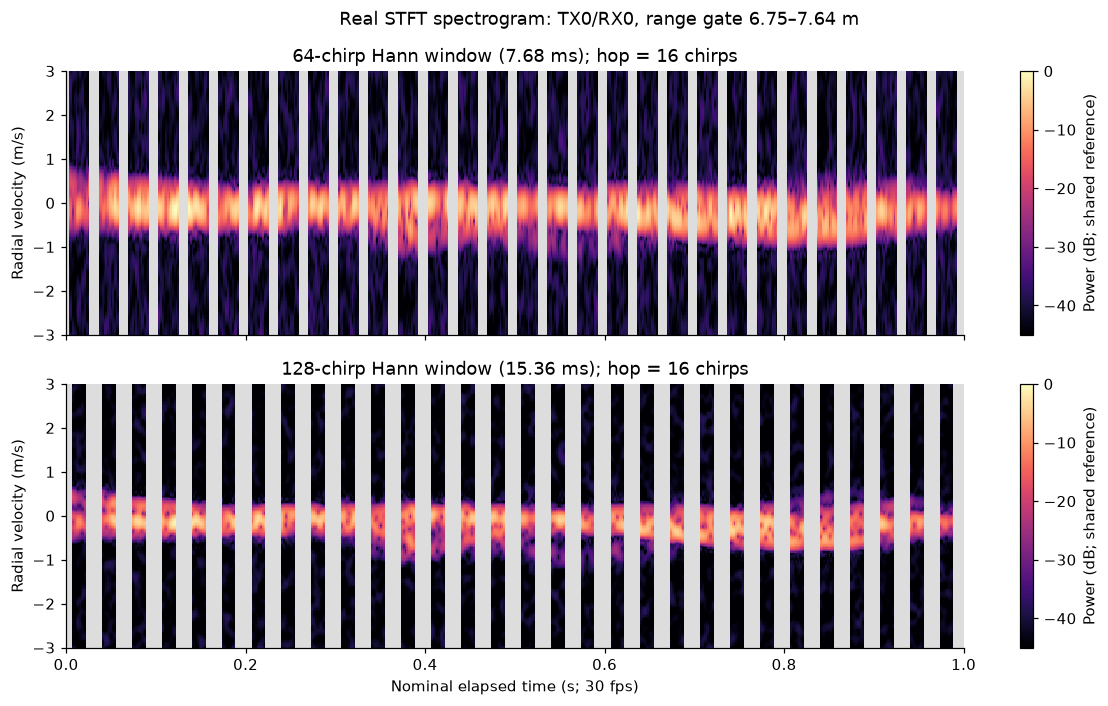

In [9]:
stft_hop, stft_nfft = 16, 512  # Use the same time step and velocity grid for both window lengths.
stft_lengths = (64, 128)  # Compare a short and a long observation window.
stft_results = {}  # Store power and coordinates for each window length.
for length in stft_lengths:  # Process the two window choices independently.
    stft_results[length] = frame_stft_power(stft_traces, length, stft_hop, stft_nfft, Tsr, lamr)  # Compute each spectrogram.
stft_reference = max(result[0].max() for result in stft_results.values())  # Use one power reference across all times and both plots.
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, sharey=True)  # Stack the two time–velocity maps.
for ax, length in zip(axes, stft_lengths):  # Draw one panel for each window length.
    power, centers, velocity = stft_results[length]  # Unpack the spectrogram and its coordinates.
    velocity_step = velocity[1] - velocity[0]  # Measure the plotted velocity-bin spacing.
    velocity_edges = np.r_[velocity - velocity_step / 2, velocity[-1] + velocity_step / 2]  # Build cell boundaries for the vertical axis.
    local_edges = np.r_[centers - stft_hop * Tsr / 2, centers[-1] + stft_hop * Tsr / 2]  # Give each window-center column one hop of width.
    ax.set_facecolor('#dddddd')  # Mark intervals with no evaluated full-window centers in gray.
    for frame_position, frame_index in enumerate(stft_frame_indices):  # Place frames separately on the nominal time axis.
        time_edges = frame_index / stft_frame_rate + local_edges  # Add the nominal frame start to local window times.
        im = ax.pcolormesh(time_edges, velocity_edges, db_power(power[frame_position], stft_reference),  # Convert power using the common reference.
                           shading='flat', cmap='magma', vmin=-45, vmax=0)  # Render one frame without filling the gaps between frames.
    ax.set(title=f'{length}-chirp Hann window ({length * Tsr * 1000:.2f} ms); hop = {stft_hop} chirps',  # Identify the time–frequency settings.
           ylabel='Radial velocity (m/s)', ylim=(-3, 3), xlim=(0, len(stft_adc) / stft_frame_rate))  # Set shared physical limits.
    ax.grid(False)  # Keep the spectrogram cells unobstructed.
    fig.colorbar(im, ax=ax, label='Power (dB; shared reference)')  # Explain the common color scale.
    print(f'{length} chirps: {len(centers)} windows/frame; velocity scale ≈ {lamr / (2 * length * Tsr):.3f} m/s')  # Report window count and a resolution scale.
axes[-1].set_xlabel('Nominal elapsed time (s; 30 fps)')  # Clearly label the frame-timing assumption.
fig.suptitle(f'Real STFT spectrogram: TX0/RX0, range gate {rr[stft_gate][0]:.2f}–{rr[stft_gate][-1]:.2f} m')  # Identify the measured signal.
finish('15_real_stft')  # Save and display the comparison for GitHub and classroom use.

### 5.4 Read the spectrogram

Pick one vertical column: it is a local Doppler spectrum. Follow a bright band horizontally to see how spectral energy evolves. Here the vertical coordinate uses the source's velocity-sign convention.

**Gray intervals** have no evaluated full-window centers: they include frame gaps and portions near frame edges. The plotted columns are spaced by the hop, but each estimate uses the full window duration. Gray does not mean zero reflected power.

**Discuss:** compare the same interval in both panels. Which has broader velocity peaks? Why does making the hop smaller fail to shorten the observation window?

A person's torso and limbs can produce different Doppler components; their motion-dependent structure is called **micro-Doppler**. This short recording and fixed range gate provide an illustration of time-varying radar spectra, not a labeled gait or limb-motion measurement. Changes can also arise from noise, interference, or a reflector entering/leaving the range gate. Mean removal can suppress stationary targets and very slow motion.

**Try it:** change `stft_center_m` or `stft_half_width_m` in Section 5.2 and rerun the following cells. Use the same gate and shared power reference when comparing window lengths.

## 6. Exit ticket

Answer the following questions, then discuss your observations:

1. Match the three spectra to the sample, chirp, and antenna axes. Which physical quantity does each estimate?
2. At the selected range, what changes near zero velocity after mean removal? Could a stationary person also disappear?
3. Record the selected peak's range, radial velocity, and angle. Why are these estimates rather than verified target labels?
4. What does one column of a spectrogram represent? How do window length and hop affect it?
5. Why do we keep STFT windows inside individual frames, and what does gray mean in the plot?

Use the printed values and saved plots; no additional code or report is required during class.
An optional follow-up is to change `selected_range_m` in Section 3 and compare the Doppler slices.

<details>
<summary>Instructor answer key — discuss before expanding</summary>

1. ADC samples → range; same-TX chirps → radial velocity; RX antennas → azimuth.
2. The stationary component is suppressed; genuine stationary targets can also be suppressed.
3. The default example selects roughly 7.19 m, −0.25 m/s, and +4.5° under the source conventions.
   These are spectral observations without independent truth or phase calibration.
   Multipath, sidelobes, noise, and multiple scattering points can contribute.
4. A column is the power of a short, windowed Doppler FFT. Longer windows improve Doppler separation at the expense of temporal localization; hop controls spacing and overlap.
5. Cross-frame timing and phase continuity are not established. Gray marks intervals without evaluated full-window centers, rather than zero power.

</details>

Continue to Section 7 to measure how far the person moves in one second.

## 7. How far does the person move in one second?

The scene photo shows one person in an otherwise empty parking lot, and Sections 3–5 found one moving return near 7 m.
The 30-frame TX0/RX0 subset from Section 5 spans about one second at the nominal 30 fps, so we can ask a physical question: **how far does the person move during that second?**

Radar gives two independent answers:

| Method | Measured in each frame | Displacement |
|---|---|---|
| **Range tracking** | *Where* the moving energy is: the power-weighted range centroid around the strongest static-suppressed return | $\Delta R = R_{\rm last}-R_{\rm first}$, or a line fit through all frames |
| **Doppler integration** | *How fast* it moves: the radial velocity of the strongest Doppler bin at that range | $\Delta R \approx \sum_i v_i\,\Delta t$, with $\Delta t = 1/30$ s |

If the two methods agree, each one checks the other.

* **Radial only.** Both methods measure motion along the radar's line of sight. Walking sideways barely changes range or Doppler, and this single-RX subset cannot track angle over time.
* **Small motion, coarse resolution.** The range-resolution scale is about 0.22 m (Section 2), and the zero-padded bin spacing is about 0.056 m. A slow walker may move only about one resolution cell, so we use a power-weighted **centroid** around each frame's peak. It interpolates the dominant reflector's position between bins; it does not add resolution.
* **Nominal timing.** As in Section 5, frame $i$ starts at $i/30$ s, and each estimate is placed at its frame's midpoint.
* **A body is not a point.** Torso and limbs reflect at slightly different ranges and velocities. Both methods follow the strongest reflector, usually the torso.

**Predict:** which estimate will look smoother over time, and which one cannot drift?

In [10]:
walk_search_m = 1.5  # Search within ±1.5 m of the range selected in Section 3.
walk_half_width_m = 0.3  # Use bins within ±0.3 m of each frame's peak for the centroid and Doppler.
walk_gate = np.abs(rr - rr[real_ri]) <= walk_search_m  # Select a fixed search interval for every frame.
walk_rr = rr[walk_gate]  # Keep the range coordinates inside the search interval.
walk_range = (np.fft.fft(stft_adc * wrr[None, None, :], n=NRr, axis=2) / wrr.sum())[:, :, walk_gate]  # Range FFT every chirp, then keep the search bins.
walk_range -= walk_range.mean(axis=1, keepdims=True)  # Remove each frame's complex slow-time mean to suppress static returns.
walk_profile = np.mean(np.abs(walk_range)**2, axis=1)  # Average moving power over chirps: [frame, range bin].
walk_doppler = np.fft.fftshift(  # Center zero Doppler for every frame.
    np.fft.fft(walk_range * wdr[None, :, None], n=NDr, axis=1), axes=1  # Window and FFT along chirps within each frame.
) / wdr.sum()  # Normalize as in Section 3.
walk_r = np.zeros(len(stft_adc))  # Store one range estimate per frame.
walk_v = np.zeros(len(stft_adc))  # Store one radial-velocity estimate per frame.
for f in range(len(stft_adc)):  # Estimate each frame independently.
    near = np.abs(walk_rr - walk_rr[np.argmax(walk_profile[f])]) <= walk_half_width_m  # Select bins around this frame's strongest moving return.
    walk_r[f] = np.sum(walk_rr[near] * walk_profile[f, near]) / np.sum(walk_profile[f, near])  # Compute the power-weighted range centroid.
    walk_v[f] = vr[np.argmax(np.mean(np.abs(walk_doppler[f][:, near])**2, axis=1))]  # Take the strongest Doppler bin's radial velocity.
del walk_doppler  # Release the per-frame Doppler cube.

walk_t = stft_frame_indices / stft_frame_rate + (stft_adc.shape[1] - 1) * Tsr / 2  # Place each estimate at its frame's nominal midpoint.
walk_duration = walk_t[-1] - walk_t[0]  # Time between the first and last frame midpoints.
walk_dr_range = walk_r - walk_r[0]  # Range method: change relative to the first frame.
walk_fit = np.polyfit(walk_t, walk_r, 1)  # Fit a straight line through all range estimates.
walk_dr_doppler = np.r_[0, np.cumsum((walk_v[1:] + walk_v[:-1]) / 2 * np.diff(walk_t))]  # Doppler method: integrate velocity with the trapezoid rule.
print(f"Search gate: {walk_rr[0]:.2f}–{walk_rr[-1]:.2f} m; TX0/RX0; {len(stft_adc)} frames over {walk_duration:.2f} s")  # Report the data used.
print(f"Range tracking:      {walk_r[0]:.2f} m -> {walk_r[-1]:.2f} m, change {walk_dr_range[-1]:+.2f} m")  # Use the first and last centroids.
print(f"Range line fit:      slope {walk_fit[0]:+.2f} m/s, change {walk_fit[0] * walk_duration:+.2f} m")  # Use all centroids.
print(f"Doppler integration: mean {np.mean(walk_v):+.2f} m/s, change {walk_dr_doppler[-1]:+.2f} m")  # Use the independent velocity estimates.

Search gate: 5.74–8.64 m; TX0/RX0; 30 frames over 0.97 s
Range tracking:      7.10 m -> 6.87 m, change -0.23 m
Range line fit:      slope -0.26 m/s, change -0.25 m
Doppler integration: mean -0.18 m/s, change -0.18 m


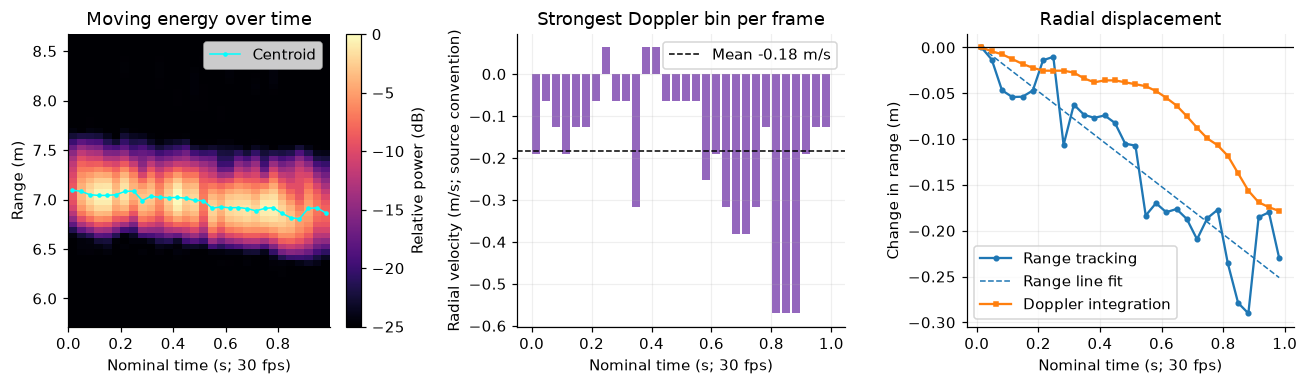

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))  # Show position, velocity, and displacement side by side.
im = axes[0].pcolormesh(walk_t, walk_rr, db_power(walk_profile).T,  # Draw moving power with time horizontally and range vertically.
                        shading="nearest", cmap="magma", vmin=-25, vmax=0)  # Give each frame one column.
axes[0].plot(walk_t, walk_r, ".-", c="cyan", ms=4, lw=1, label="Centroid")  # Overlay the range track.
axes[0].set(xlabel="Nominal time (s; 30 fps)", ylabel="Range (m)", title="Moving energy over time")  # Label the range–time map.
axes[0].grid(False)  # Hide grid lines over the heatmap.
axes[0].legend(loc="upper right")  # Identify the track.
fig.colorbar(im, ax=axes[0], label="Relative power (dB)")  # Add the map's power color scale.
axes[1].bar(walk_t, walk_v, width=0.8 / stft_frame_rate, color="tab:purple")  # Draw one velocity bar per frame.
axes[1].axhline(np.mean(walk_v), ls="--", c="k", lw=1, label=f"Mean {np.mean(walk_v):+.2f} m/s")  # Mark the average velocity.
axes[1].set(xlabel="Nominal time (s; 30 fps)", ylabel="Radial velocity (m/s; source convention)",  # Label time and velocity.
            title="Strongest Doppler bin per frame")  # Describe the velocity estimate.
axes[1].legend()  # Identify the mean line.
axes[2].plot(walk_t, walk_dr_range, "o-", c="tab:blue", ms=3, label="Range tracking")  # Plot the change in centroid range.
axes[2].plot(walk_t, walk_fit[0] * (walk_t - walk_t[0]), "--", c="tab:blue", lw=1, label="Range line fit")  # Plot the fitted slope from zero.
axes[2].plot(walk_t, walk_dr_doppler, "s-", c="tab:orange", ms=3, label="Doppler integration")  # Plot the integrated velocity.
axes[2].axhline(0, c="k", lw=0.8)  # Mark the starting position.
axes[2].set(xlabel="Nominal time (s; 30 fps)", ylabel="Change in range (m)", title="Radial displacement")  # Label the comparison.
axes[2].legend(loc="lower left")  # Identify the methods.
finish("16_real_displacement")  # Save and display the comparison.

### 7.1 Read the result

The left panel shows where the moving energy sits in each frame; the cyan centroid is the range track.
The middle panel shows how fast the strongest reflector moves in each frame.
The right panel converts both into a change in range, so the two methods share one axis.

**Discuss:**

1. How far does the person move in about one second? Do the two methods agree to within the range-resolution scale?
2. Why is the range track jumpy while the Doppler curve is smooth? Over a one-minute recording, which estimate could drift, and which could not?
3. Velocity is negative while range decreases. What does that tell you about this dataset's velocity sign convention?
4. If the person walked sideways across the radar's view at the same speed, what would these three panels show?

<details>
<summary>Instructor answer key — discuss before expanding</summary>

1. The centroid moves from about 7.10 m to 6.87 m (about −0.23 m; the line fit gives about −0.25 m). Integrating the Doppler velocity gives about −0.18 m.
   Both say the person moves roughly **0.2 m closer** in about one second, a mean radial speed near 0.2 m/s, well below a typical walking pace of about 1.2–1.4 m/s.
   The middle panel shows faster motion between about 0.6 and 0.9 s. The methods differ by about 0.05 m, roughly a quarter of the 0.22 m range-resolution scale.
2. Each centroid is an absolute position, but it shifts with body shape, limb returns, and noise below one resolution cell.
   Doppler measures velocity within each 30.6 ms frame, and integration smooths it, but any velocity bias accumulates into position drift. Range tracking cannot drift.
   Practical trackers, such as Kalman filters, combine both.
3. In this dataset's processing convention, negative velocity corresponds to decreasing range, that is, approaching the radar.
   This is an internal consistency check between two measurements, not an external calibration.
4. Range and Doppler would change little, so both methods would report almost no displacement. Measuring sideways motion requires tracking angle with several RX channels.

</details>

**End of the lesson.**

## References

* Real data, configuration, and license: [Gao et al.'s original repository](https://github.com/Xiangyu-Gao/mmWave-radar-signal-processing-and-microDoppler-classification);
  [local extraction and parameter notes](data/uw/README.md).
* Gao et al., *Experiments with mmWave Automotive Radar Test-bed*:
  [paper](https://arxiv.org/abs/1912.12566),
  [DOI](https://doi.org/10.1109/IEEECONF44664.2019.9048939).
* TI: [Intro to mmWave Sensing series](https://www.ti.com/video/series/mmwave-training-series.html),
  with modules on range, IF phase, velocity, and angle.
* TI: [Programming Chirp Parameters in TI Radar Devices, SWRA553A](https://www.ti.com/lit/an/swra553a/swra553a.pdf),
  for further details on chirp timing, bandwidth, and performance relationships.
* NumPy: [fft](https://numpy.org/doc/stable/reference/generated/numpy.fft.fft.html) and
  [fftfreq](https://numpy.org/doc/stable/reference/generated/numpy.fft.fftfreq.html).
* STFT concepts and time/frequency coordinates: [SciPy ShortTimeFFT documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.ShortTimeFFT.html).
